In [2]:
import pandas as pd
import numpy as np
import re
import os
import random
import scipy
import tensorflow as tf

from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.metrics import (
    accuracy_score,
    mean_absolute_error,
    mean_squared_error,
    classification_report,
    confusion_matrix
)

# Reproducibility
np.random.seed(42)
random.seed(42)
tf.random.set_seed(42)

print("TensorFlow:", tf.__version__)
print("SciPy:", scipy.__version__)
print("GPU available:", len(tf.config.list_physical_devices("GPU")) > 0)

# Upload amazon.csv from your computer
from google.colab import files
uploaded = files.upload()

# Load dataset
df = pd.read_csv("amazon.csv")

print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

df.head()

TensorFlow: 2.21.0
SciPy: 1.16.3
GPU available: False


Saving amazon.csv to amazon.csv
Dataset shape: (1465, 16)

Column names:
['product_id', 'product_name', 'category', 'discounted_price', 'actual_price', 'discount_percentage', 'rating', 'rating_count', 'about_product', 'user_id', 'user_name', 'review_id', 'review_title', 'review_content', 'img_link', 'product_link']


,product_id,product_name,category,discounted_price,actual_price,discount_percentage,rating,rating_count,about_product,user_id,user_name,review_id,review_title,review_content,img_link,product_link
0,B07JW9H4J1,Wayona Nylon Braided USB to Lightning Fast Cha...,Computers&Accessories|Accessories&Peripherals|...,₹399,"₹1,099",64%,4.2,"24,269",High Compatibility : Compatible With iPhone 12...,"AG3D6O4STAQKAY2UVGEUV46KN35Q,AHMY5CWJMMK5BJRBB...","Manav,Adarsh gupta,Sundeep,S.Sayeed Ahmed,jasp...","R3HXWT0LRP0NMF,R2AJM3LFTLZHFO,R6AQJGUP6P86,R1K...","Satisfied,Charging is really fast,Value for mo...",Looks durable Charging is fine tooNo complains...,https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Wayona-Braided-WN3LG1-Sy...
1,B098NS6PVG,Ambrane Unbreakable 60W / 3A Fast Charging 1.5...,Computers&Accessories|Accessories&Peripherals|...,₹199,₹349,43%,4.0,"43,994","Compatible with all Type C enabled devices, be...","AECPFYFQVRUWC3KGNLJIOREFP5LQ,AGYYVPDD7YG7FYNBX...","ArdKn,Nirbhay kumar,Sagar Viswanathan,Asp,Plac...","RGIQEG07R9HS2,R1SMWZQ86XIN8U,R2J3Y1WL29GWDE,RY...","A Good Braided Cable for Your Type C Device,Go...",I ordered this cable to connect my phone to An...,https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Ambrane-Unbreakable-Char...
2,B096MSW6CT,Sounce Fast Phone Charging Cable & Data Sync U...,Computers&Accessories|Accessories&Peripherals|...,₹199,"₹1,899",90%,3.9,"7,928",【 Fast Charger& Data Sync】-With built-in safet...,"AGU3BBQ2V2DDAMOAKGFAWDDQ6QHA,AESFLDV2PT363T2AQ...","Kunal,Himanshu,viswanath,sai niharka,saqib mal...","R3J3EQQ9TZI5ZJ,R3E7WBGK7ID0KV,RWU79XKQ6I1QF,R2...","Good speed for earlier versions,Good Product,W...","Not quite durable and sturdy,https://m.media-a...",https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Sounce-iPhone-Charging-C...
3,B08HDJ86NZ,boAt Deuce USB 300 2 in 1 Type-C & Micro USB S...,Computers&Accessories|Accessories&Peripherals|...,₹329,₹699,53%,4.2,"94,363",The boAt Deuce USB 300 2 in 1 cable is compati...,"AEWAZDZZJLQUYVOVGBEUKSLXHQ5A,AG5HTSFRRE6NL3M5S...","Omkar dhale,JD,HEMALATHA,Ajwadh a.,amar singh ...","R3EEUZKKK9J36I,R3HJVYCLYOY554,REDECAZ7AMPQC,R1...","Good product,Good one,Nice,Really nice product...","Good product,long wire,Charges good,Nice,I bou...",https://m.media-amazon.com/images/I/41V5FtEWPk...,https://www.amazon.in/Deuce-300-Resistant-Tang...
4,B08CF3B7N1,Portronics Konnect L 1.2M Fast Charging 3A 8 P...,Computers&Accessories|Accessories&Peripherals|...,₹154,₹399,61%,4.2,"16,905",[CHARGE & SYNC FUNCTION]- This cable comes wit...,"AE3Q6KSUK5P75D5HFYHCRAOLODSA,AFUGIFH5ZAFXRDSZH...","rahuls6099,Swasat Borah,Ajay Wadke,Pranali,RVK...","R1BP4L2HH9TFUP,R16PVJEXKV6QZS,R2UPDB81N66T4P,R...","As good as original,Decent,Good one for second...","Bought this instead of original apple, does th...",https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Portronics-Konnect-POR-1...


In [3]:
# Remove duplicate rows
df = df.drop_duplicates().copy()

# Remove spaces from column names
df.columns = df.columns.str.strip()

# Clean numerical values such as ₹1,099 and 64%
def clean_number(value):
    if pd.isna(value):
        return np.nan

    value = str(value).replace(",", "").replace("₹", "").replace("%", "")
    value = re.sub(r"[^0-9.\-]", "", value)

    try:
        return float(value)
    except ValueError:
        return np.nan

# Convert numerical columns
for col in [
    "discounted_price",
    "actual_price",
    "discount_percentage",
    "rating_count",
    "rating"
]:
    df[col] = df[col].apply(clean_number)

# Remove records without a valid rating
df = df[df["rating"].between(1, 5)].copy()

# Convert ratings like 4.2 into 4 stars
df["target_rating"] = df["rating"].round().astype(int)

# Fill missing text and categorical values
text_cols = [
    "product_name", "category",
    "about_product", "review_title", "review_content"
]

for col in text_cols:
    df[col] = df[col].fillna("").astype(str).str.strip()

df["category"] = df["category"].replace("", "Unknown")

# Create one review-text field
df["review_text"] = (
    df["review_title"] + " " + df["review_content"]
).str.strip()

# Use product information as model inputs
df["product_text"] = (
    df["product_name"] + " " + df["about_product"]
).str.strip()

# Missing numerical values
numeric_cols = [
    "discounted_price",
    "actual_price",
    "discount_percentage",
    "rating_count"
]

for col in numeric_cols:
    df[col] = df[col].replace([np.inf, -np.inf], np.nan)
    df[col] = df[col].fillna(df[col].median())

print("Cleaned dataset shape:", df.shape)
print("\nMissing values:")
print(df[text_cols + numeric_cols].isnull().sum())
print("\nRating distribution:")
print(df["target_rating"].value_counts().sort_index())

df[["review_text", "product_text", "rating", "target_rating"]].head()

Cleaned dataset shape: (1464, 19)

Missing values:
product_name           0
category               0
about_product          0
review_title           0
review_content         0
discounted_price       0
actual_price           0
discount_percentage    0
rating_count           0
dtype: int64

Rating distribution:
target_rating
2       2
3      40
4    1393
5      29
Name: count, dtype: int64


,review_text,product_text,rating,target_rating
0,"Satisfied,Charging is really fast,Value for mo...",Wayona Nylon Braided USB to Lightning Fast Cha...,4.2,4
1,"A Good Braided Cable for Your Type C Device,Go...",Ambrane Unbreakable 60W / 3A Fast Charging 1.5...,4.0,4
2,"Good speed for earlier versions,Good Product,W...",Sounce Fast Phone Charging Cable & Data Sync U...,3.9,4
3,"Good product,Good one,Nice,Really nice product...",boAt Deuce USB 300 2 in 1 Type-C & Micro USB S...,4.2,4
4,"As good as original,Decent,Good one for second...",Portronics Konnect L 1.2M Fast Charging 3A 8 P...,4.2,4


In [4]:
# Model inputs
X_text = df["review_text"].values
X_product = df["product_text"].values
X_category = df["category"].values

X_numeric = df[numeric_cols].to_numpy(dtype=np.float32)
y = df["target_rating"].to_numpy(dtype=np.int32)

# Encode ratings 1–5 as class indices 0–4 for Keras
y_encoded = y - 1

indices = np.arange(len(df))

train_idx, test_idx = train_test_split(
    indices,
    test_size=0.20,
    random_state=42,
    stratify=y_encoded
)

# Split text and targets
review_train = X_text[train_idx]
review_test = X_text[test_idx]

product_train = X_product[train_idx]
product_test = X_product[test_idx]

category_train = X_category[train_idx]
category_test = X_category[test_idx]

y_train = y_encoded[train_idx]
y_test = y_encoded[test_idx]

# Scale numeric features using training data only
scaler = StandardScaler()

numeric_train = scaler.fit_transform(X_numeric[train_idx]).astype("float32")
numeric_test = scaler.transform(X_numeric[test_idx]).astype("float32")

# One-hot encode category
try:
    encoder = OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    )
except TypeError:
    # Compatibility with older scikit-learn versions
    encoder = OneHotEncoder(
        handle_unknown="ignore",
        sparse=False
    )

category_train_encoded = encoder.fit_transform(
    category_train.reshape(-1, 1)
).astype("float32")

category_test_encoded = encoder.transform(
    category_test.reshape(-1, 1)
).astype("float32")

# Combine scaled numerical features and encoded categories
features_train = np.concatenate(
    [numeric_train, category_train_encoded], axis=1
).astype("float32")

features_test = np.concatenate(
    [numeric_test, category_test_encoded], axis=1
).astype("float32")

print("Training records:", len(train_idx))
print("Testing records:", len(test_idx))
print("Product feature count:", features_train.shape[1])
print("Training rating classes:", np.unique(y_train + 1))

Training records: 1171
Testing records: 293
Product feature count: 200
Training rating classes: [2 3 4 5]


In [5]:
MAX_WORDS = 10000
MAX_LENGTH = 120

# Review tokenizer
review_vectorizer = layers.TextVectorization(
    max_tokens=MAX_WORDS,
    output_mode="int",
    output_sequence_length=MAX_LENGTH,
    standardize="lower_and_strip_punctuation"
)

review_vectorizer.adapt(
    tf.data.Dataset.from_tensor_slices(review_train).batch(32)
)

# Product description tokenizer
product_vectorizer = layers.TextVectorization(
    max_tokens=MAX_WORDS,
    output_mode="int",
    output_sequence_length=MAX_LENGTH,
    standardize="lower_and_strip_punctuation"
)

product_vectorizer.adapt(
    tf.data.Dataset.from_tensor_slices(product_train).batch(32)
)

print("Review vocabulary size:", review_vectorizer.vocabulary_size())
print("Product vocabulary size:", product_vectorizer.vocabulary_size())

# Example tokenization
example = review_vectorizer(
    tf.constant(["Excellent product and very good quality"])
)

print("\nEncoded review:")
print(example.numpy())

Review vocabulary size: 10000
Product vocabulary size: 10000

Encoded review:
[[225  16   4  22  10  19   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0   0   0]]


In [6]:
# Input 1: customer review
review_input = keras.Input(
    shape=(), dtype=tf.string, name="review_input"
)

review_tokens = review_vectorizer(review_input)

review_embedding = layers.Embedding(
    input_dim=review_vectorizer.vocabulary_size(),
    output_dim=64,
    mask_zero=True
)(review_tokens)

review_features = layers.LSTM(32)(review_embedding)
review_features = layers.Dropout(0.3)(review_features)

# Input 2: product description
product_input = keras.Input(
    shape=(), dtype=tf.string, name="product_input"
)

product_tokens = product_vectorizer(product_input)

product_embedding = layers.Embedding(
    input_dim=product_vectorizer.vocabulary_size(),
    output_dim=32,
    mask_zero=True
)(product_tokens)

product_features = layers.GlobalAveragePooling1D()(product_embedding)

# Input 3: numerical and categorical product features
features_input = keras.Input(
    shape=(features_train.shape[1],),
    dtype=tf.float32,
    name="features_input"
)

structured_features = layers.Dense(
    32, activation="relu"
)(features_input)

structured_features = layers.Dropout(0.2)(structured_features)

# Combine all branches
combined = layers.Concatenate()([
    review_features,
    product_features,
    structured_features
])

combined = layers.Dense(64, activation="relu")(combined)
combined = layers.Dropout(0.3)(combined)

# Five output classes: 1, 2, 3, 4, 5 stars
output = layers.Dense(5, activation="softmax", name="rating_output")(
    combined
)

model = keras.Model(
    inputs=[review_input, product_input, features_input],
    outputs=output
)

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ review_input        │ (None)            │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ text_vectorization  │ (None, 120)       │          0 │ review_input[0][… │
│ (TextVectorization) │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ product_input       │ (None)            │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding           │ (None, 120, 64)   │    640,000 │ text_vectorizati… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal           │ (None, 120)       │          0 │ text_vectorizati… │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ text_vectorization… │ (None, 120)       │          0 │ product_input[0]… │
│ (TextVectorization) │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ features_input      │ (None, 200)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm (LSTM)         │ (None, 32)        │     12,416 │ embedding[0][0],  │
│                     │                   │            │ not_equal[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_1         │ (None, 120, 32)   │    320,000 │ text_vectorizati… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal_1         │ (None, 120)       │          0 │ text_vectorizati… │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 32)        │      6,432 │ features_input[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 32)        │          0 │ lstm[0][0]        │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 32)        │          0 │ embedding_1[0][0… │
│ (GlobalAveragePool… │                   │            │ not_equal_1[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 32)        │          0 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 96)        │          0 │ dropout[0][0],    │
│ (Concatenate)       │                   │            │ global_average_p… │
│                     │                   │            │ dropout_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 64)        │      6,208 │ concatenate[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_2 (Dropout) │ (None, 64)        │          0 │ dense_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rating_output       │ (None, 5)         │        325 │ dropout_2[0][0]   │
│ (Dense)             │                   │            │                 

 Total params: 985,381 (3.76 MB)

 Trainable params: 985,381 (3.76 MB)

 Non-trainable params: 0 (0.00 B)

In [7]:
early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

history = model.fit(
    {
        "review_input": review_train,
        "product_input": product_train,
        "features_input": features_train
    },
    y_train,
    validation_split=0.15,
    epochs=15,
    batch_size=32,
    callbacks=[early_stopping],
    verbose=1
)

Epoch 1/15
32/32 ━━━━━━━━━━━━━━━━━━━━ 15s 176ms/step - accuracy: 0.8915 - loss: 0.9267 - val_accuracy: 0.9545 - val_loss: 0.2933
Epoch 2/15
32/32 ━━━━━━━━━━━━━━━━━━━━ 4s 133ms/step - accuracy: 0.9508 - loss: 0.2787 - val_accuracy: 0.9545 - val_loss: 0.2190
Epoch 3/15
32/32 ━━━━━━━━━━━━━━━━━━━━ 4s 116ms/step - accuracy: 0.9508 - loss: 0.2515 - val_accuracy: 0.9545 - val_loss: 0.2100
Epoch 4/15
32/32 ━━━━━━━━━━━━━━━━━━━━ 4s 129ms/step - accuracy: 0.9508 - loss: 0.2351 - val_accuracy: 0.9545 - val_loss: 0.2034
Epoch 5/15
32/32 ━━━━━━━━━━━━━━━━━━━━ 3s 70ms/step - accuracy: 0.9508 - loss: 0.2312 - val_accuracy: 0.9545 - val_loss: 0.1984
Epoch 6/15
32/32 ━━━━━━━━━━━━━━━━━━━━ 4s 106ms/step - accuracy: 0.9508 - loss: 0.1939 - val_accuracy: 0.9545 - val_loss: 0.1883
Epoch 7/15
32/32 ━━━━━━━━━━━━━━━━━━━━ 3s 102ms/step - accuracy: 0.9528 - loss: 0.1404 - val_accuracy: 0.9545 - val_loss: 0.1856
Epoch 8/15
32/32 ━━━━━━━━━━━━━━━━━━━━ 2s 47ms/step - accuracy: 0.9618 - loss: 0.0961 - val_accuracy: 0.9

In [9]:
# Predict ratings on the test set
probabilities = model.predict(
    {
        "review_input": review_test,
        "product_input": product_test,
        "features_input": features_test
    },
    verbose=0
)

# Convert class indices 0–4 back to ratings 1–5
predicted_ratings = np.argmax(probabilities, axis=1) + 1
actual_ratings = y_test + 1

accuracy = accuracy_score(actual_ratings, predicted_ratings)
mae = mean_absolute_error(actual_ratings, predicted_ratings)
rmse = np.sqrt(mean_squared_error(actual_ratings, predicted_ratings))

print(f"Test Accuracy: {accuracy:.4f} ({accuracy * 100:.2f}%)")
print(f"Mean Absolute Error (MAE): {mae:.4f} stars")
print(f"Root Mean Squared Error (RMSE): {rmse:.4f} stars")

print("\nClassification Report:")
print(
    classification_report(
        actual_ratings,
        predicted_ratings,
        labels=[1, 2, 3, 4, 5],
        zero_division=0
    )
)

Test Accuracy: 0.9386 (93.86%)
Mean Absolute Error (MAE): 0.0648 stars
Root Mean Squared Error (RMSE): 0.2677 stars

Classification Report:
              precision    recall  f1-score   support

           1       0.00      0.00      0.00         0
           2       0.00      0.00      0.00         0
           3       0.00      0.00      0.00         8
           4       0.95      0.99      0.97       279
           5       0.00      0.00      0.00         6

    accuracy                           0.94       293
   macro avg       0.19      0.20      0.19       293
weighted avg       0.91      0.94      0.92       293



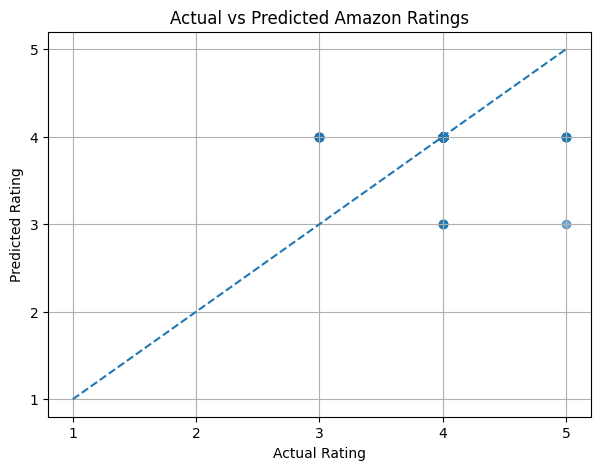

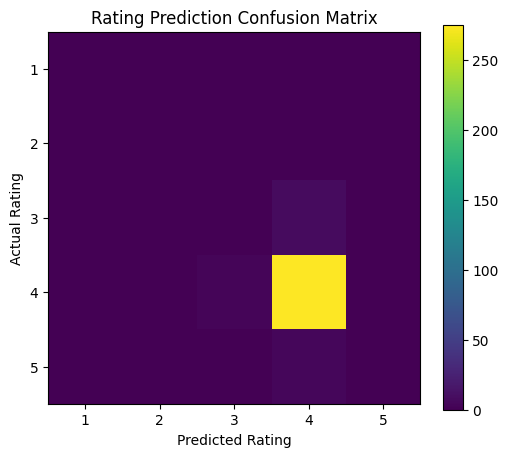

In [10]:
# Create comparison table
comparison = pd.DataFrame({
    "Review": review_test,
    "Actual Rating": actual_ratings,
    "Predicted Rating": predicted_ratings
})

comparison["Correct Prediction"] = (
    comparison["Actual Rating"] == comparison["Predicted Rating"]
)

print(comparison.head(20).to_string(index=False))

# Save all test predictions
comparison.to_csv("amazon_rating_predictions.csv", index=False)

# Plot actual vs predicted ratings
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 5))
plt.scatter(
    comparison["Actual Rating"],
    comparison["Predicted Rating"],
    alpha=0.6
)

plt.plot([1, 5], [1, 5], linestyle="--")
plt.xlabel("Actual Rating")
plt.ylabel("Predicted Rating")
plt.title("Actual vs Predicted Amazon Ratings")
plt.xticks([1, 2, 3, 4, 5])
plt.yticks([1, 2, 3, 4, 5])
plt.grid(True)
plt.show()

# Confusion matrix
cm = confusion_matrix(
    actual_ratings,
    predicted_ratings,
    labels=[1, 2, 3, 4, 5]
)

plt.figure(figsize=(6, 5))
plt.imshow(cm, interpolation="nearest")
plt.title("Rating Prediction Confusion Matrix")
plt.xlabel("Predicted Rating")
plt.ylabel("Actual Rating")
plt.xticks(range(5), [1, 2, 3, 4, 5])
plt.yticks(range(5), [1, 2, 3, 4, 5])
plt.colorbar()
plt.show()

In [13]:

def predict_rating(review, product_name, about_product, category,
                   discounted_price, actual_price,
                   discount_percentage, rating_count):

    review = str(review)
    product_text = str(product_name) + " " + str(about_product)

    # Prepare numerical features in the correct order
    numeric_values = np.array([[
        float(discounted_price),
        float(actual_price),
        float(discount_percentage),
        float(rating_count)
    ]], dtype=np.float32)

    # Remove the feature-name warning
    numeric_values = scaler.transform(numeric_values).astype(np.float32)

    # Encode category
    category_values = encoder.transform(
        np.array([[str(category)]])
    ).astype(np.float32)

    feature_values = np.concatenate(
        [numeric_values, category_values], axis=1
    ).astype(np.float32)

    # Use explicit TensorFlow tensors for all inputs
    prediction_inputs = {
        "review_input": tf.constant([review], dtype=tf.string),
        "product_input": tf.constant([product_text], dtype=tf.string),
        "features_input": tf.convert_to_tensor(
            feature_values, dtype=tf.float32
        )
    }

    # Predict rating
    probs = model(prediction_inputs, training=False).numpy()[0]

    rating = int(np.argmax(probs) + 1)
    confidence = float(np.max(probs) * 100)

    print("Customer Review:", review)
    print("Predicted Rating:", rating, "stars")
    print(f"Selected class probability: {confidence:.2f}%")

    print("\nRating Probabilities:")
    for i, prob in enumerate(probs, start=1):
        print(f"{i} star(s): {prob * 100:.2f}%")

    return rating


# Test with an unseen review
predicted_rating = predict_rating(
    review="Excellent quality and fast charging. Very useful product.",
    product_name="USB Charging Cable",
    about_product="Braided cable with fast charging support",
    category="Computers&Accessories",
    discounted_price=399,
    actual_price=1099,
    discount_percentage=64,
    rating_count=100
)

Customer Review: Excellent quality and fast charging. Very useful product.
Predicted Rating: 4 stars
Selected class probability: 98.03%

Rating Probabilities:
1 star(s): 0.03%
2 star(s): 0.15%
3 star(s): 0.99%
4 star(s): 98.03%
5 star(s): 0.79%


In [14]:
import joblib
import os

# Save trained Keras model
model.save("amazon_rating_model.keras")

# Save scaler and category encoder
joblib.dump(
    {
        "scaler": scaler,
        "encoder": encoder,
        "numeric_cols": numeric_cols
    },
    "amazon_preprocessing.pkl"
)

print("Model and preprocessing files saved successfully!")

# Download the prediction results
from google.colab import files
files.download("amazon_rating_predictions.csv")

Model and preprocessing files saved successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>